In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
df = pd.read_csv('Advertising.csv')

df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [3]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
print(df.describe())

Dataset shape: (200, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

Summary statistics:
       Unnamed: 0          TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000  200.000000
mean   100.500000  147.042500   23.264000   30.554000   14.022500
std     57.879185   85.854236   14.846809   21.778621    5.217457
min      1.000000    0.700000    0.000000    0.300000    1.600000
25%     50.750000   74.375000    9.975000   12.750000   10.375000
50%    100.500000  149.750000   22.900000   25.750000   12.900000
75%    150.250000  218.825000 

In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

Duplicate records:
0


In [5]:
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

print(df.head())

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9


In [7]:
df = df.drop_duplicates()
df = df.dropna()

print("Shape after cleaning:", df.shape)

Shape after cleaning: (200, 4)


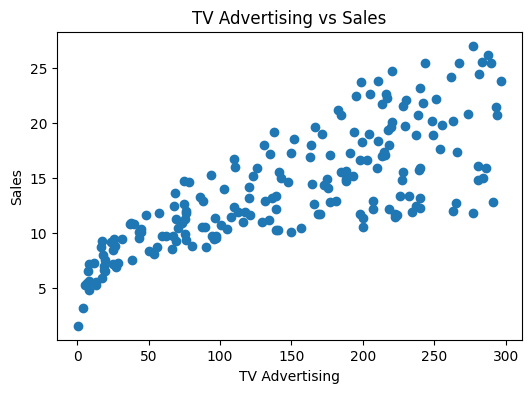

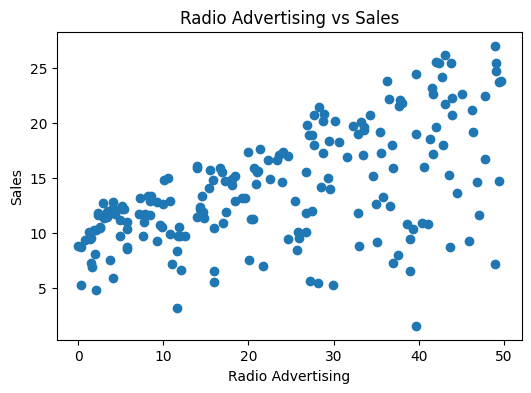

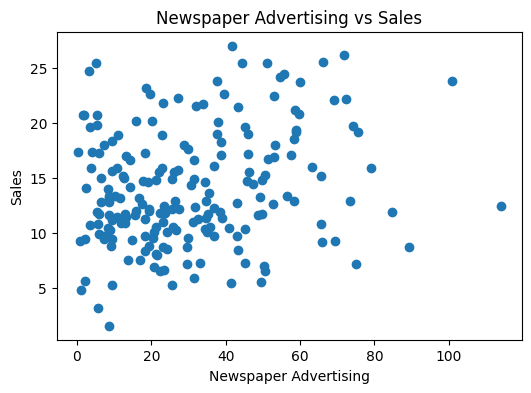

In [8]:
plt.figure(figsize=(6, 4))
plt.scatter(df['TV'], df['Sales'])
plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('TV Advertising vs Sales')
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(df['Radio'], df['Sales'])
plt.xlabel('Radio Advertising')
plt.ylabel('Sales')
plt.title('Radio Advertising vs Sales')
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(df['Newspaper'], df['Sales'])
plt.xlabel('Newspaper Advertising')
plt.ylabel('Sales')
plt.title('Newspaper Advertising vs Sales')
plt.show()

                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.782224
Radio      0.054809  1.000000   0.354104  0.576223
Newspaper  0.056648  0.354104   1.000000  0.228299
Sales      0.782224  0.576223   0.228299  1.000000


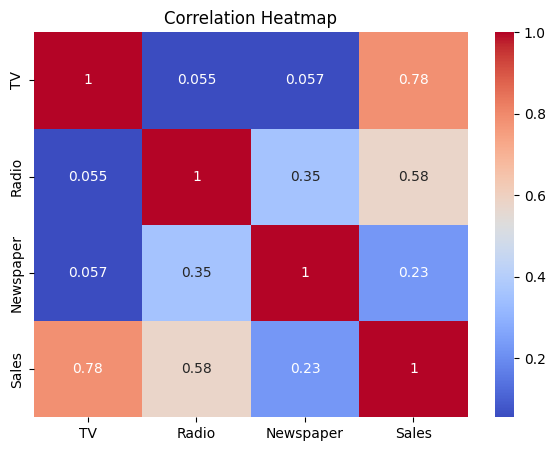

In [9]:
correlation = df.corr()

print(correlation)

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [10]:
small_data = df[['TV', 'Radio', 'Sales']].head(6)

print(small_data)

      TV  Radio  Sales
0  230.1   37.8   22.1
1   44.5   39.3   10.4
2   17.2   45.9    9.3
3  151.5   41.3   18.5
4  180.8   10.8   12.9
5    8.7   48.9    7.2


In [11]:
X_manual = np.column_stack((
    np.ones(len(small_data)),
    small_data['TV'],
    small_data['Radio']
))

y_manual = small_data['Sales'].values

print("Design Matrix X:")
print(X_manual)

print("\nTarget Vector y:")
print(y_manual)

Design Matrix X:
[[  1.  230.1  37.8]
 [  1.   44.5  39.3]
 [  1.   17.2  45.9]
 [  1.  151.5  41.3]
 [  1.  180.8  10.8]
 [  1.    8.7  48.9]]

Target Vector y:
[22.1 10.4  9.3 18.5 12.9  7.2]


In [12]:
XT = X_manual.T

XTX = XT @ X_manual
XTy = XT @ y_manual

print("X transpose X:")
print(XTX)

print("\nX transpose y:")
print(XTy)

X transpose X:
[[6.0000000e+00 6.3280000e+02 2.2400000e+02]
 [6.3280000e+02 1.1093868e+05 1.9871130e+04]
 [2.2400000e+02 1.9871130e+04 9.2936800e+03]]

X transpose y:
[   80.4  10905.68  2926.42]


In [13]:
coefficients = np.linalg.solve(XTX, XTy)

b0 = coefficients[0]
b1 = coefficients[1]
b2 = coefficients[2]

print("b0 =", b0)
print("b1 =", b1)
print("b2 =", b2)

b0 = -2.2817247582367255
b1 = 0.07303946786919824
b2 = 0.21370970215085583


In [14]:
print("Sales =", b0, "+", b1, "* TV +", b2, "* Radio")

predicted_value = b0 + b1 * small_data['TV'].iloc[0] + b2 * small_data['Radio'].iloc[0]

actual_value = small_data['Sales'].iloc[0]

residual = actual_value - predicted_value

print("Actual Sales:", actual_value)
print("Predicted Sales:", predicted_value)
print("Residual:", residual)

Sales = -2.2817247582367255 + 0.07303946786919824 * TV + 0.21370970215085583 * Radio
Actual Sales: 22.1
Predicted Sales: 22.60288353976814
Residual: -0.5028835397681384


In [15]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 160
Testing observations: 40


In [16]:
print(df.corr()['Sales'].sort_values(ascending=False))

Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


In [17]:
X_single = df[['TV']]

X_train_single, X_test_single, y_train_single, y_test_single = train_test_split(
    X_single, y, test_size=0.2, random_state=42
)

single_model = LinearRegression()

single_model.fit(X_train_single, y_train_single)

single_prediction = single_model.predict(X_test_single)

print("Single feature intercept:", single_model.intercept_)
print("Single feature coefficient:", single_model.coef_[0])
print("Single feature test R2:", r2_score(y_test_single, single_prediction))

Single feature intercept: 7.119638430592953
Single feature coefficient: 0.046529733705443346
Single feature test R2: 0.6766954295627076


In [18]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Intercept:", model.intercept_)

print("Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 2.979067338122629
Coefficients:
TV : 0.044729517468716326
Radio : 0.18919505423437652
Newspaper : 0.0027611143413671935


In [19]:
manual_model = LinearRegression()

manual_model.fit(small_data[['TV', 'Radio']], small_data['Sales'])

print("Manual calculation coefficients:", coefficients)
print("Library intercept:", manual_model.intercept_)
print("Library coefficients:", manual_model.coef_)

Manual calculation coefficients: [-2.28172476  0.07303947  0.2137097 ]
Library intercept: -2.2817247582366758
Library coefficients: [0.07303947 0.2137097 ]


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

print("Standardised coefficients:")

for feature, coefficient in zip(X.columns, scaled_model.coef_):
    print(feature, ":", coefficient)

Standardised coefficients:
TV : 3.7641961751469974
Radio : 2.7923066501984364
Newspaper : 0.05597551446265314


In [21]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

print(comparison.head(10))

   Actual Sales  Predicted Sales
0          16.9        16.408024
1          22.4        20.889882
2          21.4        21.553843
3           7.3        10.608503
4          24.7        22.112373
5          12.6        13.105592
6          22.3        21.057192
7           8.4         7.461010
8          11.5        13.606346
9          14.9        15.155070


In [22]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

n = len(y_test)
p = X_test.shape[1]

adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("Adjusted R2 Score:", adjusted_r2)

MAE: 1.4607567168117603
MSE: 3.1740973539761033
RMSE: 1.78159966153345
R2 Score: 0.899438024100912
Adjusted R2 Score: 0.8910578594426547


In [23]:
single_mae = mean_absolute_error(y_test_single, single_prediction)
single_mse = mean_squared_error(y_test_single, single_prediction)
single_rmse = np.sqrt(single_mse)
single_r2 = r2_score(y_test_single, single_prediction)

single_adjusted_r2 = 1 - (1 - single_r2) * (len(y_test_single) - 1) / (len(y_test_single) - 1 - 1)

comparison_metrics = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2', 'Adjusted R2'],
    'Single Feature Model': [
        single_mae, single_mse, single_rmse, single_r2, single_adjusted_r2
    ],
    'Multiple Feature Model': [
        mae, mse, rmse, r2, adjusted_r2
    ]
})

print(comparison_metrics)

        Metric  Single Feature Model  Multiple Feature Model
0          MAE              2.444420                1.460757
1          MSE             10.204654                3.174097
2         RMSE              3.194472                1.781600
3           R2              0.676695                0.899438
4  Adjusted R2              0.668187                0.891058


In [24]:
residuals = y_test - y_pred

print(residuals.head())

95     0.491976
15     1.510118
30    -0.153843
158   -3.308503
128    2.587627
Name: Sales, dtype: float64


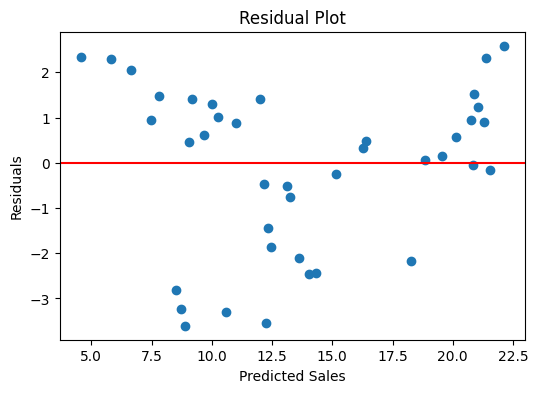

In [25]:
plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

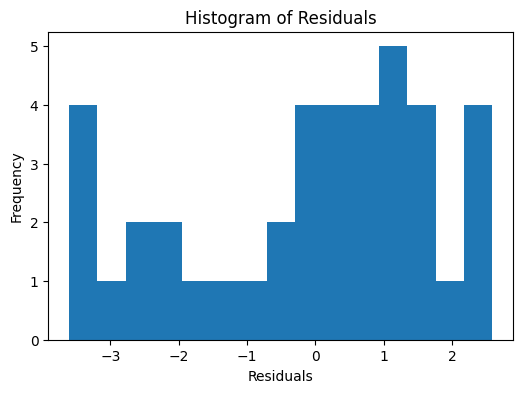

In [26]:
plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=15)
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Histogram of Residuals')
plt.show()

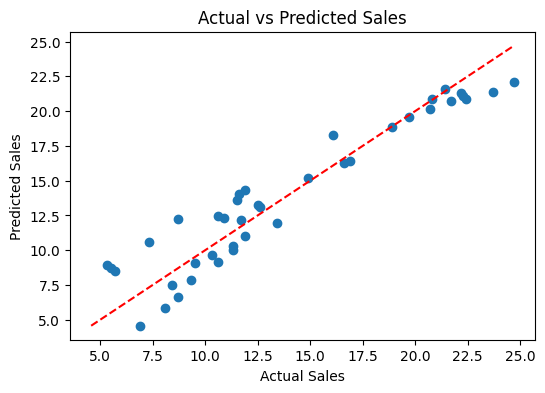

In [27]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot([minimum, maximum], [minimum, maximum], 'r--')

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.show()

In [28]:
vif_data = pd.DataFrame()

vif_data['Feature'] = X.columns

vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data)

     Feature       VIF
0         TV  1.004611
1      Radio  1.144952
2  Newspaper  1.145187


In [29]:
new_data = pd.DataFrame({
    'TV': [200],
    'Radio': [40],
    'Newspaper': [30]
})

new_prediction = model.predict(new_data)

print("Predicted Sales:", new_prediction[0])

Predicted Sales: 19.575606431481972
